<a href="https://colab.research.google.com/github/gayatrigbh02/CSL701-CE02-Machine-Learning-Lab/blob/main/Experiments%5CML_EXP_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###  ML Experiment Number 9
Student Name :

Batch :


Roll Number :



### **Aim**

To implement Classification and Regression Trees (CART) using Python on the Palmer Penguins Dataset Extended.

## Objectives

1. To understand the concept and working of the CART algorithm.
2. To implement Decision Tree Classification using Python.   
3. To visualize the constructed Decision Tree structure and decision boundaries.   
4. To analyze impurity measures such as Gini Index and Entropy.
5. To compare the decision boundary of a Decision Tree with a linear classification boundary (e.g., Logistic Regression).   
6. To evaluate and compare the performance of both classifiers.

# Relevant Theory

###Classification and Regression Trees (CART)
CART is a non-parametric supervised machine learning algorithm used for both classification and regression tasks. It builds a binary decision tree by recursively splitting the dataset based on feature values that maximize information gain or minimize impurity.

A tree consists of:

* Root Node: The topmost node representing the entire dataset.

* Internal Nodes: Decision points based on feature splits.

* Leaf/Terminal Nodes: Output class labels or predictions.

Impurity MeasuresGini Index (Gini Impurity): Measures the frequency with which a randomly chosen element from the set would be incorrectly labeled.$$Gini(D) = 1 - \sum_{i=1}^{k} p_i^2$$where $p_i$ is the probability of an item belonging to class $i$.Entropy & Information Gain: Measures the amount of impurity or randomness in the data.$$Entropy(D) = -\sum_{i=1}^{k} p_i \log_2(p_i)$$Dataset InformationGet the Palmer Penguins Dataset Extended from Kaggle using the following link:https://www.kaggle.com/datasets/samybaladram/palmers-penguin-dataset-extended The Palmer Penguins dataset contains measurements of penguin species across islands in the Palmer Archipelago:AdelieChinstrapGentooThe primary numerical features are:culmen_length_mm (or bill_length_mm)culmen_depth_mm (or bill_depth_mm)flipper_length_mmbody_mass_gFor visualization, we will use: culmen_length_mm and flipper_length_mm.

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Palmer Penguins Extended dataset.
---

In [2]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.linear_model import LogisticRegression

# Upload dataset
uploaded = files.upload()

# Get uploaded CSV filename
filename = list(uploaded.keys())[0]

# Load dataset
df = pd.read_csv(filename)

# Display first 5 rows in proper DataFrame format
display(df.head())

# Display dataset shape
print("\nDataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
display(pd.DataFrame(df.columns, columns=["Column Names"]))

Saving palmerpenguins_extended.csv to palmerpenguins_extended (1).csv


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,diet,life_stage,health_metrics,year
0,Adelie,Biscoe,53.4,17.8,219.0,5687.0,female,fish,adult,overweight,2021
1,Adelie,Biscoe,49.3,18.1,245.0,6811.0,female,fish,adult,overweight,2021
2,Adelie,Biscoe,55.7,16.6,226.0,5388.0,female,fish,adult,overweight,2021
3,Adelie,Biscoe,38.0,15.6,221.0,6262.0,female,fish,adult,overweight,2021
4,Adelie,Biscoe,60.7,17.9,177.0,4811.0,female,fish,juvenile,overweight,2021



Dataset Shape: (3430, 11)

Column Names:


,Column Names
0,species
1,island
2,bill_length_mm
3,bill_depth_mm
4,flipper_length_mm
5,body_mass_g
6,sex
7,diet
8,life_stage
9,health_metrics


# Task 2: Select Features and Target & Preprocess

* Handle missing values (e.g., drop rows with missing values or impute with median).   
* Select features ($X$) such as culmen_length_mm, culmen_depth_mm, flipper_length_mm, body_mass_g and set species as the target label ($y$).   
* Encode categorical targets if necessary using LabelEncoder.

In [3]:
# Check which feature names are available
if 'culmen_length_mm' in df.columns:
    length_col = 'culmen_length_mm'
    depth_col = 'culmen_depth_mm'
else:
    length_col = 'bill_length_mm'
    depth_col = 'bill_depth_mm'

# Select required columns
features = [length_col, depth_col, 'flipper_length_mm', 'body_mass_g']

# Keep only required features and target
data = df[features + ['species']].copy()

# Remove rows containing missing values
data = data.dropna()

# Define input features X
X = data[features]

# Define target y
y = data['species']

# Encode target labels
le = LabelEncoder()
y_encoded = le.fit_transform(y)

print("Features used:")
print(features)

print("\nSpecies Classes:")
print(le.classes_)

print("\nDataset Shape After Preprocessing:", data.shape)

print("\nMissing Values:")
print(data.isnull().sum())

Features used:
['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']

Species Classes:
['Adelie' 'Chinstrap' 'Gentoo']

Dataset Shape After Preprocessing: (3430, 5)

Missing Values:
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
species              0
dtype: int64


# Task 3: Split the Data

* Divide the dataset into training and testing sets using train_test_split.

In [4]:
# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

Training Data Shape: (2744, 4)
Testing Data Shape: (686, 4)


# Task 4: Implement CART Classifier

* Create a DecisionTreeClassifier model using the Gini criterion (or Entropy).   
* Fit the model on the training data and make predictions on the test set.   

In [5]:
# Create CART classifier using Gini Index
cart_model = DecisionTreeClassifier(
    criterion='gini',
    random_state=42
)

# Train the model
cart_model.fit(X_train, y_train)

# Make predictions
y_pred_cart = cart_model.predict(X_test)

print("CART Model Trained Successfully")

print("\nPredicted Classes:")
print(y_pred_cart[:10])

print("\nActual Classes:")
print(y_test[:10])

CART Model Trained Successfully

Predicted Classes:
[2 2 0 0 2 2 1 0 0 0]

Actual Classes:
[0 2 0 0 0 2 1 0 2 0]


# Task 5: Evaluate CART Model

* Accuracy: Calculate classification accuracy.   
* Confusion Matrix: Generate the matrix to analyze misclassifications across species.
* Classification Report: Output Precision, Recall, F1-Score, and Support.   

In [6]:
# Calculate accuracy
cart_accuracy = accuracy_score(y_test, y_pred_cart)

print("CART Accuracy:", cart_accuracy)
print("CART Accuracy (%):", cart_accuracy * 100)

# Confusion Matrix
cm_cart = confusion_matrix(y_test, y_pred_cart)

print("\nConfusion Matrix:")
print(cm_cart)

# Classification Report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_cart,
    target_names=le.classes_
))

CART Accuracy: 0.4518950437317784
CART Accuracy (%): 45.18950437317784

Confusion Matrix:
[[155  64  93]
 [ 48  33  44]
 [ 76  51 122]]

Classification Report:
              precision    recall  f1-score   support

      Adelie       0.56      0.50      0.52       312
   Chinstrap       0.22      0.26      0.24       125
      Gentoo       0.47      0.49      0.48       249

    accuracy                           0.45       686
   macro avg       0.42      0.42      0.42       686
weighted avg       0.46      0.45      0.46       686



# Task 6: Visualize Decision Tree & Decision Boundary

* Visualize Tree Structure: Plot the decision tree diagram using sklearn.tree.plot_tree.
* Select 2-D Features: Select culmen_length_mm and flipper_length_mm.   
* Train 2-D Model & Plot Boundary: Train the decision tree on 2D data and plot axis-aligned rectangular decision boundaries along with data points


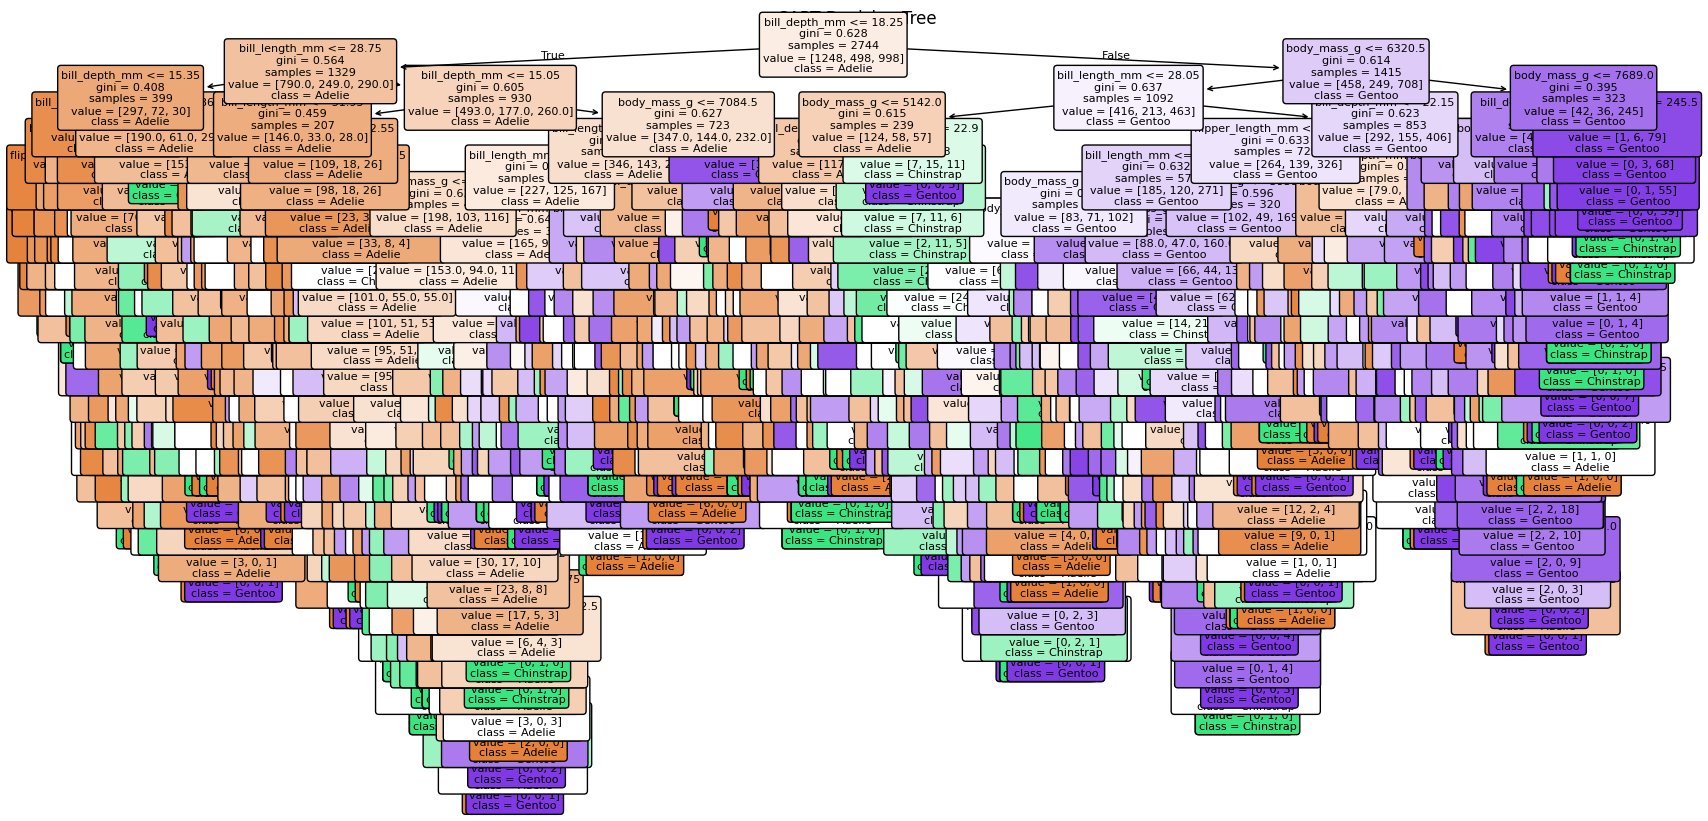

In [10]:
# Visualize the CART Decision Tree
plt.figure(figsize=(20, 10))

plot_tree(
    cart_model,
    feature_names=X.columns,
    class_names=le.classes_,
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("CART Decision Tree")
plt.show()

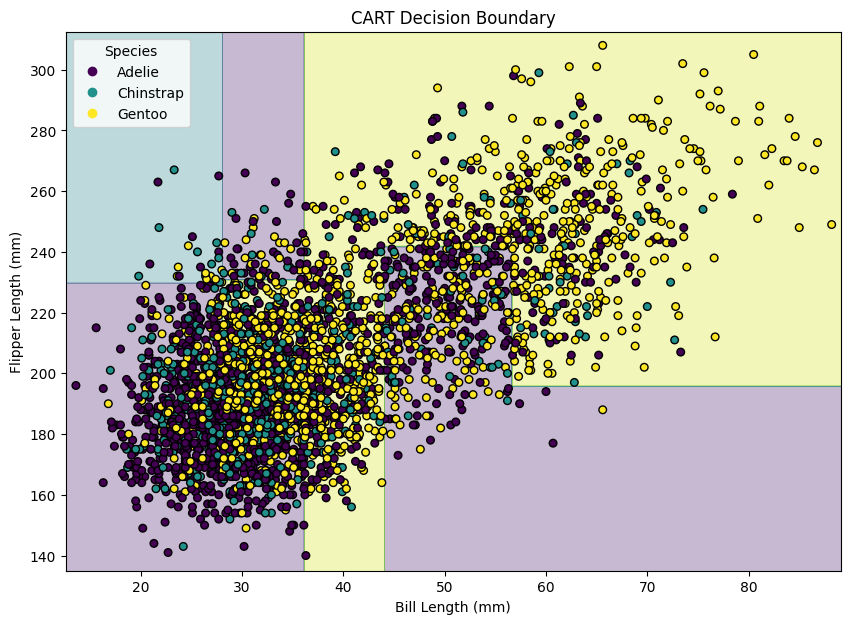

In [13]:
# Select two features
X_2d = data[['bill_length_mm', 'flipper_length_mm']]
y_2d = y_encoded

# Split the data
X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d,
    y_2d,
    test_size=0.2,
    random_state=42,
    stratify=y_2d
)

# Create a CART model with limited depth
cart_2d = DecisionTreeClassifier(
    criterion='gini',
    max_depth=4,
    random_state=42
)

# Train the model
cart_2d.fit(X_train_2d, y_train_2d)

# Define graph range
x_min = X_2d['bill_length_mm'].min() - 1
x_max = X_2d['bill_length_mm'].max() + 1

y_min = X_2d['flipper_length_mm'].min() - 5
y_max = X_2d['flipper_length_mm'].max() + 5

# Create mesh grid
xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.1),
    np.arange(y_min, y_max, 0.5)
)

# Create DataFrame containing grid points
grid = pd.DataFrame({
    'bill_length_mm': xx.ravel(),
    'flipper_length_mm': yy.ravel()
})

# Predict each grid point
Z = cart_2d.predict(grid)
Z = Z.reshape(xx.shape)

# Plot decision regions
plt.figure(figsize=(10, 7))

plt.contourf(
    xx,
    yy,
    Z,
    alpha=0.3,
    cmap='viridis'
)

# Plot actual data points
scatter = plt.scatter(
    X_2d['bill_length_mm'],
    X_2d['flipper_length_mm'],
    c=y_2d,
    cmap='viridis',
    edgecolor='black',
    s=30
)

# Add legend
handles, _ = scatter.legend_elements()

plt.legend(
    handles,
    le.classes_,
    title="Species"
)

# Labels
plt.xlabel("Bill Length (mm)")
plt.ylabel("Flipper Length (mm)")
plt.title("CART Decision Boundary")

plt.show()

# Task 7: Normal Linear Classification Boundary

* Train a Logistic Regression model using the same two features as a normal linear baseline.   
* Visualize its linear decision boundary.

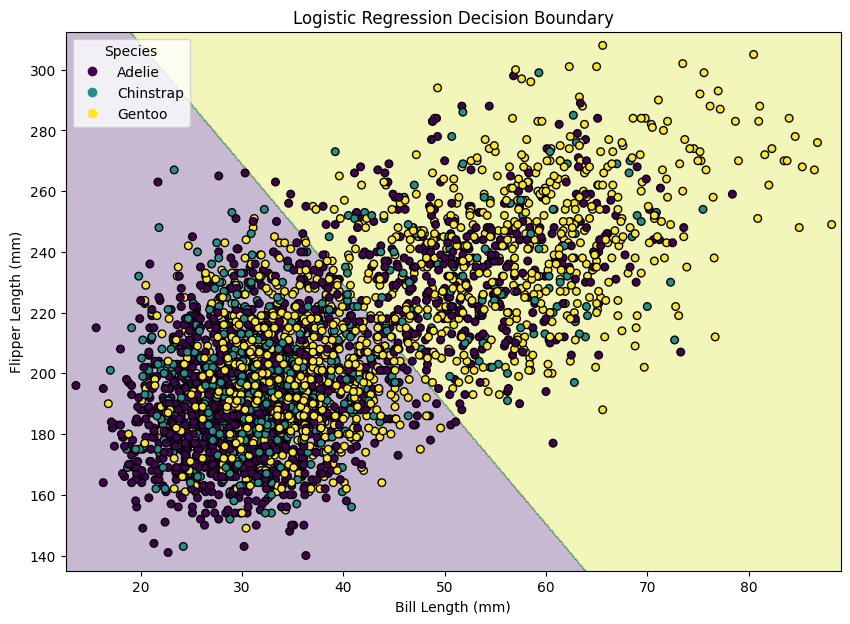

In [14]:
# Create Logistic Regression model
log_model_2d = LogisticRegression(max_iter=1000)

# Train the model using the same two features
log_model_2d.fit(X_train_2d, y_train_2d)

# Predict classes for all grid points
Z_log = log_model_2d.predict(grid)

# Reshape predictions according to mesh grid
Z_log = Z_log.reshape(xx.shape)

# Plot Logistic Regression decision boundary
plt.figure(figsize=(10, 7))

plt.contourf(
    xx,
    yy,
    Z_log,
    alpha=0.3,
    cmap='viridis'
)

# Plot actual penguin data points
scatter = plt.scatter(
    X_2d['bill_length_mm'],
    X_2d['flipper_length_mm'],
    c=y_2d,
    cmap='viridis',
    edgecolor='black',
    s=30
)

# Add species legend
handles, _ = scatter.legend_elements()

plt.legend(
    handles,
    le.classes_,
    title="Species"
)

# Add labels and title
plt.xlabel("Bill Length (mm)")
plt.ylabel("Flipper Length (mm)")
plt.title("Logistic Regression Decision Boundary")

plt.show()

# Task 8: Compare CART and Normal Linear Boundary

* Plot both the Decision Tree (axis-aligned non-linear) and Logistic Regression (linear) decision boundaries on side-by-side subplots.   * Compare how non-linear CART boundaries differ from straight linear hyperplanes.

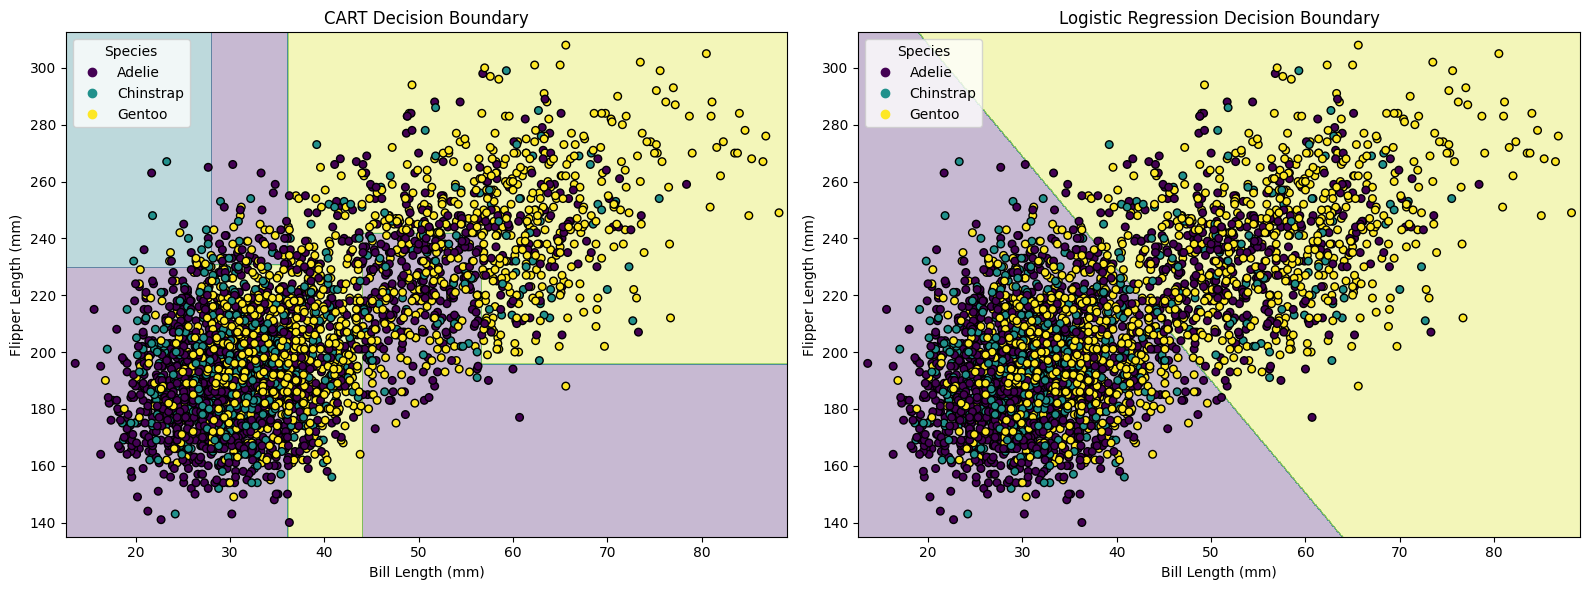

In [15]:
# Create side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ---------------- CART Decision Boundary ----------------
axes[0].contourf(
    xx,
    yy,
    Z,
    alpha=0.3,
    cmap='viridis'
)

scatter1 = axes[0].scatter(
    X_2d['bill_length_mm'],
    X_2d['flipper_length_mm'],
    c=y_2d,
    cmap='viridis',
    edgecolor='black',
    s=30
)

axes[0].set_xlabel("Bill Length (mm)")
axes[0].set_ylabel("Flipper Length (mm)")
axes[0].set_title("CART Decision Boundary")

# Add legend
handles1, _ = scatter1.legend_elements()

axes[0].legend(
    handles1,
    le.classes_,
    title="Species"
)

# ------------- Logistic Regression Boundary -------------
axes[1].contourf(
    xx,
    yy,
    Z_log,
    alpha=0.3,
    cmap='viridis'
)

scatter2 = axes[1].scatter(
    X_2d['bill_length_mm'],
    X_2d['flipper_length_mm'],
    c=y_2d,
    cmap='viridis',
    edgecolor='black',
    s=30
)

axes[1].set_xlabel("Bill Length (mm)")
axes[1].set_ylabel("Flipper Length (mm)")
axes[1].set_title("Logistic Regression Decision Boundary")

# Add legend
handles2, _ = scatter2.legend_elements()

axes[1].legend(
    handles2,
    le.classes_,
    title="Species"
)

# Adjust spacing
plt.tight_layout()

# Display plots
plt.show()

# Task 9: Compare Performance

* Compare the evaluation metrics (Accuracy, Confusion Matrix, Classification Report) of the CART Classifier vs. Logistic Regression.

In [17]:
# Create Logistic Regression model using all 4 features
log_model = LogisticRegression(max_iter=5000)

# Train Logistic Regression model
log_model.fit(X_train, y_train)

# Make predictions on test data
y_pred_log = log_model.predict(X_test)

# Calculate accuracies
cart_accuracy = accuracy_score(y_test, y_pred_cart)
log_accuracy = accuracy_score(y_test, y_pred_log)

# Display accuracy comparison
print("CART Accuracy:", cart_accuracy)
print("Logistic Regression Accuracy:", log_accuracy)

# Display CART Confusion Matrix
print("\nCART Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_cart))

# Display Logistic Regression Confusion Matrix
print("\nLogistic Regression Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_log))

# Display CART Classification Report
print("\nCART Classification Report:")
print(classification_report(
    y_test,
    y_pred_cart,
    target_names=le.classes_
))

# Display Logistic Regression Classification Report
print("\nLogistic Regression Classification Report:")
print(classification_report(
    y_test,
    y_pred_log,
    target_names=le.classes_
))


# Create performance comparison table
comparison = pd.DataFrame({
    'Model': ['CART', 'Logistic Regression'],
    'Accuracy': [cart_accuracy, log_accuracy],
    'Accuracy (%)': [cart_accuracy * 100, log_accuracy * 100]
})

display(comparison)

CART Accuracy: 0.4518950437317784
Logistic Regression Accuracy: 0.5787172011661808

CART Confusion Matrix:
[[155  64  93]
 [ 48  33  44]
 [ 76  51 122]]

Logistic Regression Confusion Matrix:
[[240   0  72]
 [ 85   0  40]
 [ 92   0 157]]

CART Classification Report:
              precision    recall  f1-score   support

      Adelie       0.56      0.50      0.52       312
   Chinstrap       0.22      0.26      0.24       125
      Gentoo       0.47      0.49      0.48       249

    accuracy                           0.45       686
   macro avg       0.42      0.42      0.42       686
weighted avg       0.46      0.45      0.46       686


Logistic Regression Classification Report:
              precision    recall  f1-score   support

      Adelie       0.58      0.77      0.66       312
   Chinstrap       0.00      0.00      0.00       125
      Gentoo       0.58      0.63      0.61       249

    accuracy                           0.58       686
   macro avg       0.39      0.47   

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


,Model,Accuracy,Accuracy (%)
0,CART,0.451895,45.189504
1,Logistic Regression,0.578717,57.871720


# Conclusion

The experiment successfully demonstrated the implementation of the Classification and Regression Tree (CART) algorithm using the Palmer Penguins Extended dataset. The dataset was preprocessed to handle missing values before training. The decision tree structure was visualized, showcasing the hierarchical splits based on feature thresholds. A comparison with a normal linear boundary (Logistic Regression) highlighted CART's ability to create non-linear, axis-aligned decision boundaries to separate different penguin species.